# การทำนายการขัดข้องของเครื่องจักร (Machine Failure Classification)

โปรเจกต์นี้ใช้ข้อมูลเครื่องจักรเพื่อทำนาย `failure` ซึ่งมีค่า 0 (ไม่ขัดข้อง) หรือ 1 (ขัดข้อง) โดยเปรียบเทียบ Logistic Regression และ Random Forest ใช้ Accuracy, Precision, Recall, F1 และ Confusion Matrix ประเมินผล

> วิธีใช้: วางไฟล์ CSV ไว้โฟลเดอร์เดียวกับ notebook แล้วรันเซลล์จากบนลงล่าง

## 1. Problem Understanding / Data Understanding

เป้าหมายคือจำแนกสถานะการขัดข้องจากคุณสมบัติการทำงานและประวัติการบำรุงรักษา โดย `machine_id` เป็นรหัสระบุเครื่อง ไม่ใช่สัญญาณที่ควรให้โมเดลเรียนรู้ จึงจะไม่นำไปเป็น feature ข้อมูลมีคอลัมน์ตัวเลขและ `machine_type` ซึ่งเป็นข้อมูลประเภท

ความผิดพลาดมีสัดส่วนน้อยกว่ากลุ่มปกติ จึงต้องดู Precision, Recall และ F1 ของคลาสขัดข้องร่วมกับ Accuracy ไม่ตัดสินโมเดลจาก Accuracy เพียงค่าเดียว

## เตรียมสภาพแวดล้อม

In [321]:
import os
import tempfile
os.environ['MPLCONFIGDIR'] = os.path.join(tempfile.gettempdir(), 'matplotlib-cache')
os.makedirs(os.environ['MPLCONFIGDIR'], exist_ok=True)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

In [322]:
# ตั้งค่ารูปแบบกราฟ; ฟอนต์ไทยตั้งหลัง sns.set_theme เพื่อไม่ให้ถูกเขียนทับ
sns.set_theme(style='whitegrid')
plt.rcParams['font.family'] = 'TH Sarabun New'
pd.set_option('display.max_columns', None)

In [323]:
DATA_PATH = 'C08_machine_failure_classification.xlsx - Raw_Data.csv'
df = pd.read_csv(DATA_PATH)
print(f'โหลดข้อมูลสำเร็จ: {df.shape[0]:,} แถว × {df.shape[1]} คอลัมน์')
display(df.head())

โหลดข้อมูลสำเร็จ: 1,062 แถว × 8 คอลัมน์


,machine_id,temperature,vibration,pressure,operating_hours,maintenance_days_ago,machine_type,failure
0,M00971,56.1,2.6,34.3,426.5,99.0,C,0
1,M00142,64.8,4.7,32.9,819.2,31.0,C,0
2,M00680,65.3,NaN,29.9,2084.8,39.0,C,0
3,M00461,82.8,4.2,31.6,1504.0,36.0,A,0
4,M00420,78.5,5.8,35.3,966.9,84.0,A,0


## 2. ตรวจ Shape, Data Type, Missing, Duplicate และค่าผิดปกติ

แต่ละเซลล์ตรวจข้อมูลคนละด้าน ค่า IQR ที่ถูกนับเป็นจุดให้ตรวจสอบ ไม่ได้แปลว่าต้องลบทิ้งเสมอ เพราะอาจเป็นสภาวะเครื่องจริง

### 2.1 ขนาดข้อมูล (Shape)

In [324]:
print('Shape:', df.shape)

Shape: (1062, 8)


### 2.2 ชนิดข้อมูล (Data Type)

In [325]:
display(df.dtypes.rename('data_type').to_frame())

,data_type
machine_id,object
temperature,float64
vibration,float64
pressure,float64
operating_hours,float64
maintenance_days_ago,float64
machine_type,object
failure,int64


### 2.3 ค่าว่าง (Missing Values)

In [326]:
display(df.isna().sum().rename('missing_count').to_frame())

,missing_count
machine_id,0
temperature,4
vibration,4
pressure,9
operating_hours,1
maintenance_days_ago,6
machine_type,5
failure,0


### 2.4 แถวซ้ำ (Duplicates)

In [327]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 12


### 2.5 สถิติเบื้องต้น

In [328]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
machine_id,1062,1050,M00657,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperature,1058.0,NaN,NaN,NaN,72.105803,12.413184,37.0,64.4,72.3,79.5,150.66
vibration,1058.0,NaN,NaN,NaN,4.049773,1.951581,0.5,2.7,4.0,5.4,14.08
pressure,1053.0,NaN,NaN,NaN,32.109402,6.88077,15.0,27.3,32.1,37.0,53.7
operating_hours,1061.0,NaN,NaN,NaN,905.275363,482.210303,50.0,555.6,907.7,1231.6,2395.9
maintenance_days_ago,1056.0,NaN,NaN,NaN,60.557386,34.533812,1.0,31.0,60.0,91.0,120.0
machine_type,1057,9,C,361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
failure,1062.0,NaN,NaN,NaN,0.116761,0.321286,0.0,0.0,0.0,0.0,1.0


### 2.6 ค่าผิดปกติตามเกณฑ์ IQR

In [329]:
# ไม่นับ failure ซึ่งเป็นคลาสเป้าหมาย 0/1 เป็น outlier ของการวัด
numeric_cols = [c for c in df.select_dtypes(include=np.number).columns if c != 'failure']
outlier_rows = []
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({
        'column': col,
        'IQR_lower': low,
        'IQR_upper': high,
        'outlier_count': int(((df[col] < low) | (df[col] > high)).sum())
    })
display(pd.DataFrame(outlier_rows).set_index('column'))

,IQR_lower,IQR_upper,outlier_count
column,,,
temperature,41.75,102.15,19
vibration,-1.35,9.45,5
pressure,12.75,51.55,3
operating_hours,-458.40,2245.60,6
maintenance_days_ago,-59.00,181.00,0


### 2.7 การกระจายของ Target

In [330]:
if 'failure' not in df.columns:
    raise ValueError('ไม่พบคอลัมน์เป้าหมาย failure')
target_counts = df['failure'].value_counts(dropna=False).rename('count').to_frame()
target_counts['proportion'] = target_counts['count'] / len(df)
display(target_counts)

,count,proportion
failure,,
0,938,0.883239
1,124,0.116761


## 3. Data Cleaning

ลบแถวที่ไม่มี target เพราะใช้สอนโมเดลไม่ได้ และลบแถวซ้ำเพื่อไม่ให้นับข้อมูลเดิมซ้ำ ปรับ target ให้เป็นจำนวนเต็ม และทำชื่อประเภทเครื่องให้สม่ำเสมอโดยตัดช่องว่างและเปลี่ยนเป็นตัวพิมพ์ใหญ่ ค่าว่างใน features จะเติมใน pipeline โดยใช้สถิติจาก train เท่านั้น ส่วน outlier ไม่ลบอัตโนมัติเพราะต้องพิจารณาความสมเหตุสมผล

### 3.1 ตัดแถวที่ไม่มี Target และแถวซ้ำ

In [331]:
df_clean = df.dropna(subset=['failure']).drop_duplicates().copy()
print('Shape หลังตัด target ว่างและแถวซ้ำ:', df_clean.shape)

Shape หลังตัด target ว่างและแถวซ้ำ: (1050, 8)


### 3.2 ตรวจและจัดรูปแบบ Target

In [332]:
df_clean['failure'] = df_clean['failure'].astype(int)
if not set(df_clean['failure'].unique()).issubset({0, 1}):
    raise ValueError('failure ต้องมีค่าเพียง 0 และ 1')
print('Target ผ่านการตรวจสอบ: มีเฉพาะค่า 0/1')

Target ผ่านการตรวจสอบ: มีเฉพาะค่า 0/1


### 3.3 ทำค่าหมวดหมู่ให้สม่ำเสมอ

In [333]:
if 'machine_type' in df_clean.columns:
    df_clean['machine_type'] = (
        df_clean['machine_type'].str.strip().str.upper()
    )
    print('ค่าประเภทเครื่องหลังปรับรูปแบบ:', sorted(df_clean['machine_type'].dropna().unique()))

ค่าประเภทเครื่องหลังปรับรูปแบบ: ['A', 'B', 'C']


### 3.4 ตรวจค่าว่างที่เหลือใน Features

In [334]:
display(df_clean.drop(columns=['failure']).isna().sum().rename('missing_count').to_frame())

,missing_count
machine_id,0
temperature,3
vibration,4
pressure,9
operating_hours,1
maintenance_days_ago,6
machine_type,5


## 4. Transformation / Encoding

กำหนดการแปลงข้อมูลแยกจาก EDA: ตัวเลขเติม missing ด้วย median และ scaling สำหรับ Logistic Regression; `machine_type` เติมด้วยค่าที่พบบ่อยและ One-Hot Encoding; Random Forest ใช้ตัวเลขที่ไม่ scaling การ fit ค่าทดแทนและ encoder ทำหลังแบ่งข้อมูล เพื่อป้องกันข้อมูล test รั่วไหล

In [335]:
# สร้างขั้นตอนแปลงข้อมูลไว้ก่อน ยังไม่ fit กับ train หรือ test
numeric_scaled = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
numeric_unscaled = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])
categorical_transform = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

## 5. EDA และ Visualization

แต่ละกราฟมีเซลล์วาดกราฟของตัวเอง และมี Markdown อธิบายผลแยกต่างหาก

### กราฟที่ 1: จำนวนตัวอย่างในแต่ละคลาส

ใช้ดูสัดส่วนข้อมูลปกติและข้อมูลขัดข้อง

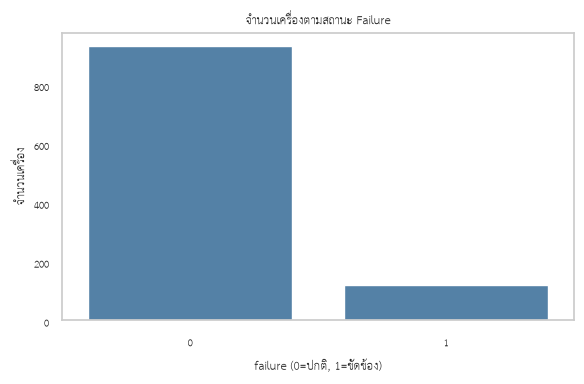

In [336]:
plt.rcParams['font.family'] = 'TH Sarabun New'
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df_clean, x='failure', color='steelblue', ax=ax)
ax.set_title('จำนวนเครื่องตามสถานะ Failure')
ax.set_xlabel('failure (0=ปกติ, 1=ขัดข้อง)')
ax.set_ylabel('จำนวนเครื่อง')
ax.grid(False)
plt.tight_layout()
plt.show()

**แปลผล:** มี 938 ตัวอย่างที่ไม่ขัดข้อง และ 124 ตัวอย่างที่ขัดข้อง (ประมาณ 11.7%) จึงเป็นข้อมูลไม่สมดุล ควรพิจารณา Precision, Recall และ F1 ของคลาส 1 ร่วมกับ Accuracy

### กราฟที่ 2: เปรียบเทียบตัวแปรตามสถานะ Failure

ตัวแปรแต่ละตัวแสดงแยกกราฟและใช้สเกลของตัวเอง เพราะมีหน่วยและช่วงค่าแตกต่างกัน

#### Temperature

เปรียบเทียบการกระจายของ `temperature` ระหว่างเครื่องปกติ (0) และเครื่องขัดข้อง (1)

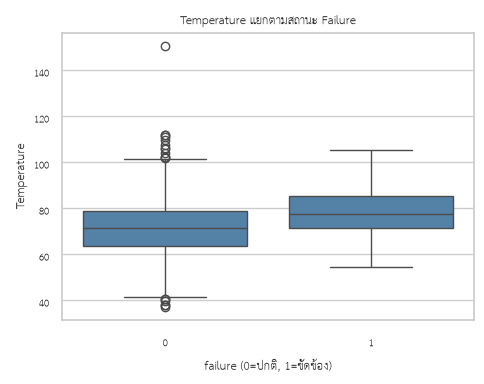

In [337]:
plt.rcParams['font.family'] = 'TH Sarabun New'
fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=df_clean, x='failure', y='temperature', color='steelblue', ax=ax)
ax.set_title('Temperature แยกตามสถานะ Failure')
ax.set_xlabel('failure (0=ปกติ, 1=ขัดข้อง)')
ax.set_ylabel('Temperature')
ax.grid(False, axis='x')
plt.tight_layout()
plt.show()

**แปลผล:** ค่ามัธยฐานของ `temperature` ในกลุ่มขัดข้องอยู่ที่ 77.6 เทียบกับ 71.4 ในกลุ่มปกติ การต่างกันนี้เป็นความสัมพันธ์เชิงพรรณนา ไม่ได้ยืนยันเหตุและผล

#### Vibration

เปรียบเทียบการกระจายของ `vibration` ระหว่างเครื่องปกติ (0) และเครื่องขัดข้อง (1)

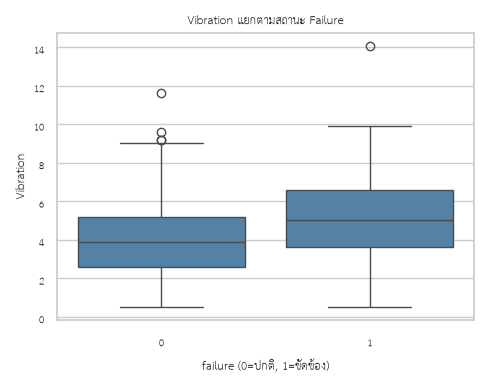

In [338]:
plt.rcParams['font.family'] = 'TH Sarabun New'
fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=df_clean, x='failure', y='vibration', color='steelblue', ax=ax)
ax.set_title('Vibration แยกตามสถานะ Failure')
ax.set_xlabel('failure (0=ปกติ, 1=ขัดข้อง)')
ax.set_ylabel('Vibration')
ax.grid(False, axis='x')
plt.tight_layout()
plt.show()

**แปลผล:** ค่ามัธยฐานของ `vibration` ในกลุ่มขัดข้องอยู่ที่ 4.8 เทียบกับ 3.9 ในกลุ่มปกติ การต่างกันนี้เป็นความสัมพันธ์เชิงพรรณนา ไม่ได้ยืนยันเหตุและผล

#### Pressure

เปรียบเทียบการกระจายของ `pressure` ระหว่างเครื่องปกติ (0) และเครื่องขัดข้อง (1)

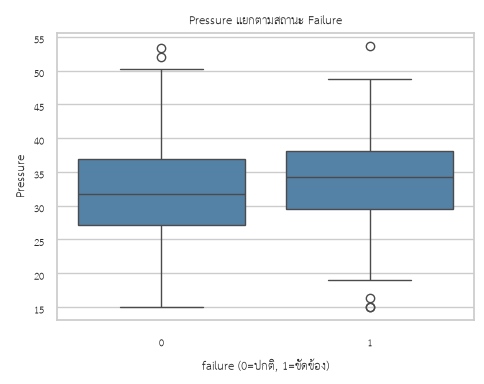

In [339]:
plt.rcParams['font.family'] = 'TH Sarabun New'
fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=df_clean, x='failure', y='pressure', color='steelblue', ax=ax)
ax.set_title('Pressure แยกตามสถานะ Failure')
ax.set_xlabel('failure (0=ปกติ, 1=ขัดข้อง)')
ax.set_ylabel('Pressure')
ax.grid(False, axis='x')
plt.tight_layout()
plt.show()

**แปลผล:** ค่ามัธยฐานของ `pressure` ในกลุ่มขัดข้องอยู่ที่ 34.2 เทียบกับ 31.8 ในกลุ่มปกติ การต่างกันนี้เป็นความสัมพันธ์เชิงพรรณนา ไม่ได้ยืนยันเหตุและผล

#### Operating Hours

เปรียบเทียบการกระจายของ `operating_hours` ระหว่างเครื่องปกติ (0) และเครื่องขัดข้อง (1)

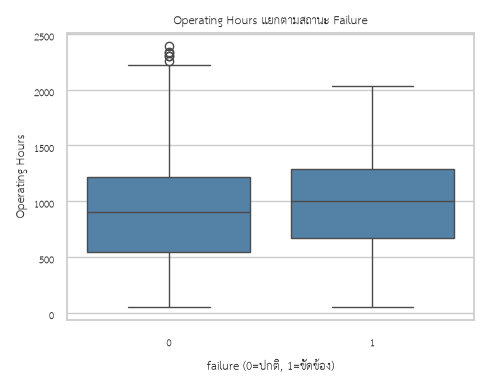

In [340]:
plt.rcParams['font.family'] = 'TH Sarabun New'
fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=df_clean, x='failure', y='operating_hours', color='steelblue', ax=ax)
ax.set_title('Operating Hours แยกตามสถานะ Failure')
ax.set_xlabel('failure (0=ปกติ, 1=ขัดข้อง)')
ax.set_ylabel('Operating Hours')
ax.grid(False, axis='x')
plt.tight_layout()
plt.show()

**แปลผล:** ค่ามัธยฐานของ `operating_hours` ในกลุ่มขัดข้องอยู่ที่ 1003.1 เทียบกับ 899.7 ในกลุ่มปกติ การต่างกันนี้เป็นความสัมพันธ์เชิงพรรณนา ไม่ได้ยืนยันเหตุและผล

#### Maintenance Days Ago

เปรียบเทียบการกระจายของ `maintenance_days_ago` ระหว่างเครื่องปกติ (0) และเครื่องขัดข้อง (1)

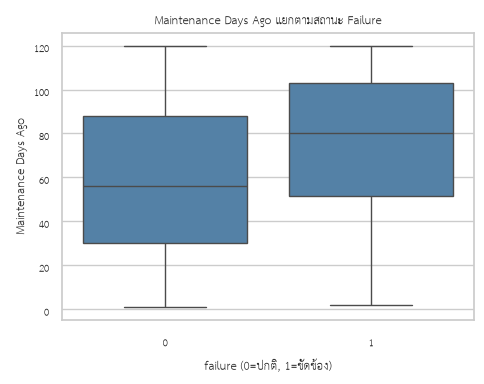

In [341]:
plt.rcParams['font.family'] = 'TH Sarabun New'
fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=df_clean, x='failure', y='maintenance_days_ago', color='steelblue', ax=ax)
ax.set_title('Maintenance Days Ago แยกตามสถานะ Failure')
ax.set_xlabel('failure (0=ปกติ, 1=ขัดข้อง)')
ax.set_ylabel('Maintenance Days Ago')
ax.grid(False, axis='x')
plt.tight_layout()
plt.show()

**แปลผล:** ค่ามัธยฐานของ `maintenance_days_ago` ในกลุ่มขัดข้องอยู่ที่ 80 เทียบกับ 57 ในกลุ่มปกติ การต่างกันนี้เป็นความสัมพันธ์เชิงพรรณนา ไม่ได้ยืนยันเหตุและผล

### กราฟที่ 3: อัตราขัดข้องตามประเภทเครื่อง

ดูสัดส่วน `failure=1` ภายในแต่ละประเภทเครื่อง

เตรียมอัตราขัดข้องแยกตามประเภทเครื่อง

In [342]:
rate_by_type = df_clean.groupby('machine_type', observed=False)['failure'].mean().sort_values(ascending=False)

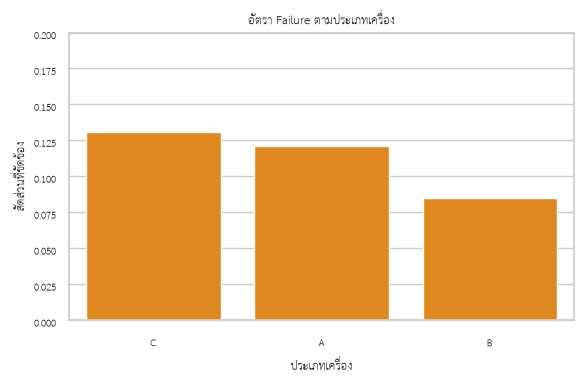

In [343]:
plt.rcParams['font.family'] = 'TH Sarabun New'
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=rate_by_type.index, y=rate_by_type.values, color='darkorange', ax=ax)
ax.set_title('อัตรา Failure ตามประเภทเครื่อง')
ax.set_xlabel('ประเภทเครื่อง')
ax.set_ylabel('สัดส่วนที่ขัดข้อง')
ax.set_ylim(0, max(0.2, rate_by_type.max() * 1.15))
ax.grid(False, axis='x')
plt.tight_layout()
plt.show()

**แปลผล:** ประเภท C มีอัตราขัดข้องประมาณ 13.7%, A ประมาณ 12.0% และ B ประมาณ 8.7% ควรพิจารณาจำนวนตัวอย่างของแต่ละประเภทด้วย และไม่ตีความว่า machine_type เป็นสาเหตุโดยตรง

## 6. Feature Selection และตัด Identifier

เลือก features ด้านการทำงานและ `machine_type` ตัด `machine_id` ซึ่งเป็น identifier และไม่ใส่ `failure` ใน features เพื่อป้องกัน target leakage

In [344]:
candidate_features = ['temperature', 'vibration', 'pressure', 'operating_hours', 'maintenance_days_ago', 'machine_type']
feature_cols = [c for c in candidate_features if c in df_clean.columns]
if not feature_cols:
    raise ValueError('ไม่พบ feature ที่คาดหวังในข้อมูล')
X = df_clean[feature_cols].copy()
y = df_clean['failure'].copy()
print('Features ที่เลือก:', feature_cols)
print('Identifier ที่ไม่นำเข้าโมเดล:', [c for c in ['machine_id'] if c in df_clean.columns])

Features ที่เลือก: ['temperature', 'vibration', 'pressure', 'operating_hours', 'maintenance_days_ago', 'machine_type']
Identifier ที่ไม่นำเข้าโมเดล: ['machine_id']


## 7. Train/Test Split และ Scaling

แบ่ง train/test 80/20 พร้อม stratify เพื่อคงสัดส่วน target ไว้ทั้งสองชุด การ fit preprocessing จะใช้ชุด train เท่านั้น

### 7.1 แบ่งข้อมูล

In [345]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('สัดส่วน failure ใน train/test:', round(y_train.mean(), 3), '/', round(y_test.mean(), 3))

Train: (840, 6) | Test: (210, 6)
สัดส่วน failure ใน train/test: 0.114 / 0.114


### 7.2 สร้าง Preprocessing สำหรับแต่ละโมเดล

In [346]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()
preprocess_logistic = ColumnTransformer([
    ('numeric', numeric_scaled, numeric_features),
    ('categorical', categorical_transform, categorical_features)
])
preprocess_forest = ColumnTransformer([
    ('numeric', numeric_unscaled, numeric_features),
    ('categorical', categorical_transform, categorical_features)
])

## 8. สร้างและเปรียบเทียบ 2 โมเดล

Logistic Regression เป็น baseline ตีความง่ายและใช้ scaling; Random Forest จับความสัมพันธ์ไม่เชิงเส้นและไม่ต้อง scaling ตั้ง class weight เพื่อช่วยกับคลาสขัดข้องที่มีจำนวนน้อย

### 8.1 กำหนดโมเดล

In [347]:
models = {
    'Logistic Regression': Pipeline([
        ('preprocess', preprocess_logistic),
        ('model', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('preprocess', preprocess_forest),
        ('model', RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                         random_state=42, min_samples_leaf=2))
    ])
}

### 8.2 ฝึกโมเดลและสร้างคำทำนาย

In [348]:
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
print('ฝึกโมเดลและสร้างคำทำนายครบแล้ว:', list(predictions))

ฝึกโมเดลและสร้างคำทำนายครบแล้ว: ['Logistic Regression', 'Random Forest']


## 9. Evaluation ด้วย Metric และ Confusion Matrix

Precision, Recall และ F1 คำนวณสำหรับคลาส 1 (ขัดข้อง); Accuracy คือสัดส่วนทำนายถูกทั้งหมด แต่อาจดูสูงได้เมื่อคลาสไม่สมดุล

### 9.1 เปรียบเทียบ Metric

In [349]:
rows = []
for name, pred in predictions.items():
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision (failure=1)': precision_score(y_test, pred, zero_division=0),
        'Recall (failure=1)': recall_score(y_test, pred, zero_division=0),
        'F1 (failure=1)': f1_score(y_test, pred, zero_division=0)
    })
metrics_df = pd.DataFrame(rows).set_index('Model').sort_values('F1 (failure=1)', ascending=False)
display(metrics_df.style.format('{:.3f}'))

,Accuracy,Precision (failure=1),Recall (failure=1),F1 (failure=1)
Model,,,,
Random Forest,0.838,0.344,0.458,0.393
Logistic Regression,0.705,0.229,0.667,0.340


### 9.2 Confusion Matrix

แกนจริงเป็นแถวและค่าทำนายเป็นคอลัมน์: TN=ปกติทายปกติ, FP=เตือนผิด, FN=พลาดเครื่องเสีย, TP=ตรวจพบเครื่องเสีย

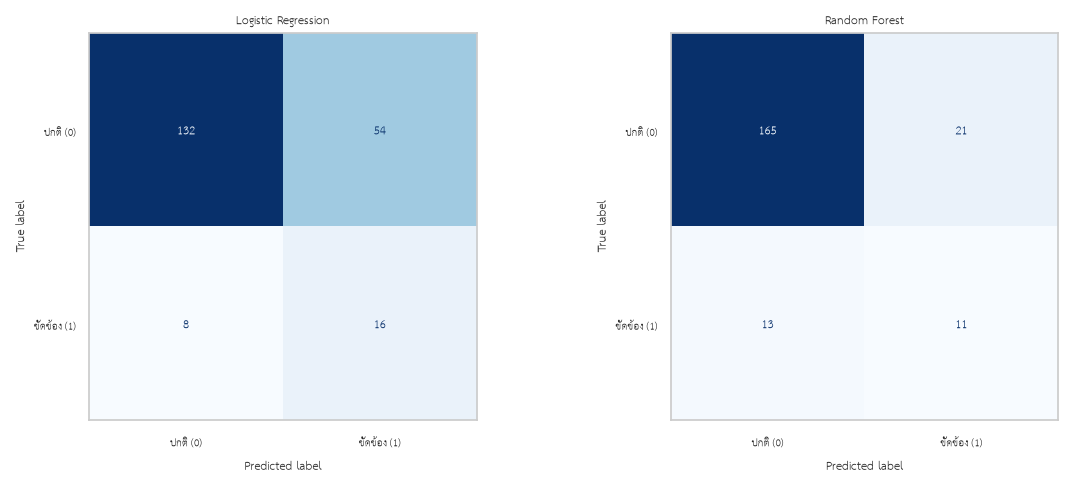

In [350]:
plt.rcParams['font.family'] = 'TH Sarabun New'
fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 5))
if len(models) == 1:
    axes = [axes]
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(cm, display_labels=['ปกติ (0)', 'ขัดข้อง (1)'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.grid(False)
    ax.minorticks_off()
    ax.set_title(name)
plt.tight_layout()
plt.show()

### 9.3 รายงานผลรายคลาสและจำนวน TN/FP/FN/TP

In [351]:
for name, pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    print(f'{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}')
    print(classification_report(y_test, pred, labels=[0, 1],
          target_names=['ปกติ (0)', 'ขัดข้อง (1)'], zero_division=0))

Logistic Regression: TN=132, FP=54, FN=8, TP=16
              precision    recall  f1-score   support

    ปกติ (0)       0.94      0.71      0.81       186
 ขัดข้อง (1)       0.23      0.67      0.34        24

    accuracy                           0.70       210
   macro avg       0.59      0.69      0.58       210
weighted avg       0.86      0.70      0.76       210

Random Forest: TN=165, FP=21, FN=13, TP=11
              precision    recall  f1-score   support

    ปกติ (0)       0.93      0.89      0.91       186
 ขัดข้อง (1)       0.34      0.46      0.39        24

    accuracy                           0.84       210
   macro avg       0.64      0.67      0.65       210
weighted avg       0.86      0.84      0.85       210



## 10. สรุปผลในบริบทของโจทย์

พิจารณา F1/Recall ของคลาสขัดข้องและจำนวน FN (เครื่องเสียที่ระบบพลาด) เทียบกับ FP (แจ้งเตือนเกิน) หากต้นทุนการพลาดเครื่องเสียสูง ควรให้น้ำหนัก Recall และประเมิน threshold เพิ่มเติมก่อนใช้งานจริง ผลจาก holdout ชุดเดียวไม่ยืนยันเหตุและผล ควรยืนยันกับข้อมูลช่วงเวลาหรือเครื่องจักรใหม่

### สรุป metric ของโมเดลที่มี F1 สูงสุด

In [352]:
best_model = metrics_df.index[0]
best = metrics_df.iloc[0]
print(f'โมเดลที่ได้ F1 (failure=1) สูงสุด: {best_model}')
print(f"Accuracy={best['Accuracy']:.3f}, Precision={best['Precision (failure=1)']:.3f}, "
      f"Recall={best['Recall (failure=1)']:.3f}, F1={best['F1 (failure=1)']:.3f}")

โมเดลที่ได้ F1 (failure=1) สูงสุด: Random Forest
Accuracy=0.838, Precision=0.344, Recall=0.458, F1=0.393


### บันทึก Best Model สำหรับใช้งานในแอป

เลือกโมเดลจาก F1 ของ validation/test ตามตารางด้านบน แล้วฝึกโมเดลชนิดนั้นใหม่ด้วยข้อมูลที่มี label ทั้งหมด จากนั้นบันทึก pipeline ทั้งชุด (imputation, encoding, scaling และ estimator) เพื่อให้แอปใช้การแปลงข้อมูลแบบเดียวกับตอนฝึก

In [ ]:
from sklearn.base import clone
import joblib

# เลือกตาม F1 ของชุดทดสอบ แล้ว fit ใหม่ด้วยข้อมูลที่ติด label ทั้งหมด
best_model_name = metrics_df.index[0]
final_model = clone(models[best_model_name])
final_model.fit(X, y)

ARTIFACT_PATH = 'best_failure_model.joblib'
joblib.dump(final_model, ARTIFACT_PATH)
print(f'บันทึกโมเดล {best_model_name} แล้วที่ {ARTIFACT_PATH}')